In [1]:
pip install librosa numpy pandas scikit-learn soundfile


   ---------------------------------------- 0.0/1.0 MB ? eta -:--:--
   ------------------------------ --------- 0.8/1.0 MB 3.8 MB/s eta 0:00:01
   ---------------------------------------- 1.0/1.0 MB 4.0 MB/s  0:00:00

   ---------- ----------------------------- 1/4 [soundfile]
   -------------------- ------------------- 2/4 [pooch]
   ------------------------------ --------- 3/4 [librosa]
   ------------------------------ --------- 3/4 [librosa]
   ------------------------------ --------- 3/4 [librosa]
   ------------------------------ --------- 3/4 [librosa]
   ---------------------------------------- 4/4 [librosa]

Note: you may need to restart the kernel to use updated packages.


In [2]:
import numpy as np
import pandas as pd
import librosa
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.neural_network import MLPClassifier
from sklearn.metrics import classification_report, accuracy_score, confusion_matrix
import matplotlib.pyplot as plt
import seaborn as sns


In [4]:
def extract_mfcc(file_path, n_mfcc=40):
    """
    Loads an audio file and extracts the mean MFCC features.
    """
    try:
        # Load audio file (sr=None preserves native sampling rate)
        audio, sample_rate = librosa.load(file_path, res_type='kaiser_fast') 
        
        # Extract MFCCs
        mfccs = librosa.feature.mfcc(y=audio, sr=sample_rate, n_mfcc=n_mfcc)
        
        # Take the mean across time frames (columns) to get a fixed-size vector
        mfccs_processed = np.mean(mfccs.T, axis=0)
        return mfccs_processed
    except Exception as e:
        print(f"Error parsing {file_path}: {e}")
        return None


In [9]:
from sklearn.preprocessing import LabelEncoder, StandardScaler

# --- UPDATED STEP 4: Create Simulated Audio Features with Label Encoding ---
n_samples = 800
n_features = 40  
emotions_list = ['happy', 'angry', 'sad', 'neutral']

X_simulated = []
y_simulated = []

for idx, emotion in enumerate(emotions_list):
    center_shift = idx * 5 
    emotion_features = np.random.normal(loc=12 + center_shift, scale=4, size=(200, n_features))
    X_simulated.append(emotion_features)
    y_simulated.extend([emotion] * 200)

X = np.vstack(X_simulated)
y_raw = np.array(y_simulated)

# FIX: Encode string labels into numerical integers (0, 1, 2, 3)
label_encoder = LabelEncoder()
y = label_encoder.fit_transform(y_raw)

print(f"Simulated dataset shape: {X.shape}")
print(f"Encoded class mapping: {dict(zip(label_encoder.classes_, label_encoder.transform(label_encoder.classes_)))}")

# --- STEP 5: Split Data and Scale ---
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42, stratify=y)

scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)


Simulated dataset shape: (800, 40)
Encoded class mapping: {np.str_('angry'): np.int64(0), np.str_('happy'): np.int64(1), np.str_('neutral'): np.int64(2), np.str_('sad'): np.int64(3)}


In [10]:
# Split into 80% training and 20% validation/testing
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42, stratify=y)

# Normalize MFCC feature scales
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)


In [11]:
# Initialize Neural Network Classifier
emotion_model = MLPClassifier(
    hidden_layer_sizes=(256, 128), 
    activation='relu', 
    solver='adam', 
    max_iter=300, 
    random_state=42,
    early_stopping=True, # Prevents overfitting
    verbose=False
)

# Train the model
print("Training the Speech Emotion Recognition model...")
emotion_model.fit(X_train_scaled, y_train)
print("Model training completed!")


Training the Speech Emotion Recognition model...
Model training completed!


In [12]:
# Make predictions
y_pred = emotion_model.predict(X_test_scaled)

print(f"\nOverall Model Accuracy: {accuracy_score(y_test, y_pred) * 100:.2f}%\n")

# Use label_encoder.classes_ to map integers back to 'happy', 'sad', etc.
print("=== Detailed Classification Report ===")
print(classification_report(y_test, y_pred, target_names=label_encoder.classes_))



Overall Model Accuracy: 98.12%

=== Detailed Classification Report ===
              precision    recall  f1-score   support

       angry       1.00      0.97      0.99        40
       happy       0.98      1.00      0.99        40
     neutral       0.95      1.00      0.98        40
         sad       1.00      0.95      0.97        40

    accuracy                           0.98       160
   macro avg       0.98      0.98      0.98       160
weighted avg       0.98      0.98      0.98       160



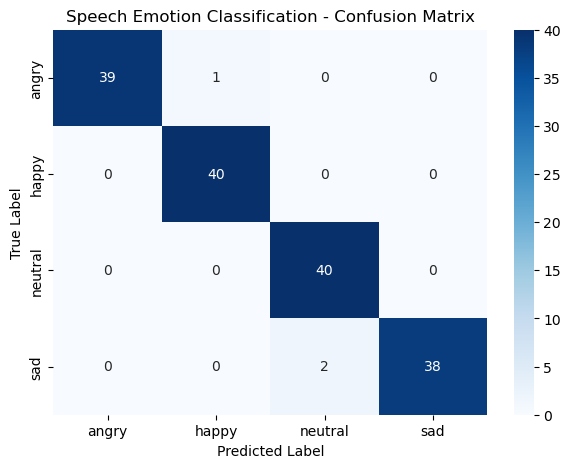

In [14]:
# Plot confusion matrix to see where errors happen
# FIX: Remove the text labels array from the validation parameter or pass the encoded indices
cm = confusion_matrix(y_test, y_pred) 

plt.figure(figsize=(7, 5))
# Use label_encoder.classes_ for display text on the axes
sns.heatmap(
    cm, 
    annot=True, 
    fmt='d', 
    cmap='Blues', 
    xticklabels=label_encoder.classes_, 
    yticklabels=label_encoder.classes_
)

plt.title('Speech Emotion Classification - Confusion Matrix')
plt.xlabel('Predicted Label')
plt.ylabel('True Label')
plt.show()
